# Iteration 0 Baseline: Handcrafted Aggregate Features

This notebook builds a stronger classical baseline using a small handcrafted aggregate feature set over gaze and driving signals.

It keeps:
- the same 4-class task
- the same fixed subject folds
- the same scenario windows

It compares:
- logistic regression
- linear SVM

In [1]:
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "dataset" / "README.md").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root containing dataset/README.md.")

root = find_project_root(Path.cwd().resolve())
dbm_repo = root / "dataset"
data_dir = root / "data" / "IDD"

version = "no-video"
# version = "only-scaled-rgb-video"

chunk_duration_s = 30.0
chunks_per_scenario = 1
rebuild_feature_table = False
progress_every = 25

artifact_dir = root / "artifacts" / "handcrafted_baseline"
artifact_dir.mkdir(parents=True, exist_ok=True)
feature_table_path = artifact_dir / "handcrafted_feature_table.pkl"

root

WindowsPath('C:/projects/DriverStateNet')

In [2]:
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

for name in list(sys.modules):
    if name == "data" or name.startswith("data."):
        sys.modules.pop(name, None)
    if name == "hail_datasets" or name.startswith("hail_datasets."):
        sys.modules.pop(name, None)

import src.classical_baseline as classical_baseline
import src.data_bootstrap as data_bootstrap
import src.handcrafted_baseline as handcrafted_baseline
import src

importlib.reload(classical_baseline)
importlib.reload(data_bootstrap)
importlib.reload(handcrafted_baseline)
importlib.reload(src)

from src import (
    LABEL_ORDER,
    build_handcrafted_dataset,
    build_handcrafted_feature_table,
    build_scenario_manifest,
    ensure_dbm_derived_features,
    ensure_processed_dataset,
    handcrafted_feature_columns_from_table,
    run_fixed_fold_linear_svm_baseline,
    run_fixed_fold_logistic_baseline,
)

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
np.set_printoptions(suppress=True)

## 1. Load the Dataset and Manifest

This baseline uses a small handcrafted feature set, so it only needs the tabular modalities.

In [3]:
processed_root = ensure_processed_dataset(
    dbm_repo=dbm_repo,
    processed_root=data_dir,
    version=version,
    download_if_missing=False,
    prompt_for_license=False,
)

derived_status = pd.DataFrame.from_dict(
    ensure_dbm_derived_features(
        dbm_repo=dbm_repo,
        processed_root=processed_root,
        run_missing=False,
    ),
    orient="index",
).sort_index()
display(derived_status)

manifest_path = root / "artifacts" / "bootstrap" / "scenario_manifest.csv"
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    print(f"Loaded manifest from {manifest_path}")
else:
    manifest = build_scenario_manifest(
        dbm_repo=dbm_repo,
        processed_root=processed_root,
        scenario_name_filter=r"driving/[0-9].*",
    )
    manifest_path = artifact_dir / "scenario_manifest.csv"
    manifest.to_csv(manifest_path, index=False)
    print(f"Built and saved manifest to {manifest_path}")

display(
    pd.DataFrame(
        {
            "num_scenarios": [len(manifest)],
            "num_participants": [manifest["participant_name"].nunique()],
            "num_folds": [manifest["fixed_fold"].nunique()],
            "num_labels": [manifest["impairment_label"].nunique()],
        }
    )
)

,relative_dir,probe_file,present,generated
ego_tracks,Resampled_previous_10_derived,ego_tracks.csv,True,False
gaze_fixation_saccade,Resampled_previous_60_derived,gaze_fixation_saccade.csv,True,False
gaze_pitch_yaw,Resampled_previous_60_derived,gaze_pitch_yaw.csv,True,False
steering_reversals,Resampled_previous_10_derived,steering_reversals.csv,True,False


Loaded manifest from C:\projects\DriverStateNet\artifacts\bootstrap\scenario_manifest.csv


,num_scenarios,num_participants,num_folds,num_labels
0,371,52,5,4


In [4]:
handcrafted_dataset = build_handcrafted_dataset(
    dbm_repo=dbm_repo,
    processed_root=processed_root,
    scenario_name_filter=r"driving/[0-9].*",
    chunk_strategy="end",
    chunk_duration_s=chunk_duration_s,
    chunks_per_scenario=chunks_per_scenario,
    chunk_end_offset_s=0.0,
)

print(f"Dataset length: {len(handcrafted_dataset)}")

chunk_fps not specified - using max feature frame rate of 60.
Constructed dataset contains 52 participants, 371 scenarios, and 371 chunks.
Dataset length: 371


## 2. Build the Handcrafted Aggregate Feature Table

Each 30-second scenario window is converted into a compact feature vector with values like:
- speed and acceleration summaries
- steering reversal rates
- pupil diameter mean
- gaze pitch/yaw variability
- fixation/saccade change rates

In [5]:
if feature_table_path.exists() and not rebuild_feature_table:
    feature_table = pd.read_pickle(feature_table_path)
    print(f"Loaded cached handcrafted feature table from {feature_table_path}")
else:
    feature_table = build_handcrafted_feature_table(
        handcrafted_dataset,
        manifest=manifest,
        progress_every=progress_every,
    )
    feature_table.to_pickle(feature_table_path)
    feature_table.to_csv(artifact_dir / "handcrafted_feature_table.csv", index=False)
    print(f"Saved handcrafted feature table to {feature_table_path}")

feature_columns = handcrafted_feature_columns_from_table(feature_table)

display(
    pd.DataFrame(
        {
            "num_rows": [len(feature_table)],
            "num_feature_columns": [len(feature_columns)],
            "num_participants": [feature_table["participant_name"].nunique()],
            "num_folds": [feature_table["fixed_fold"].nunique()],
        }
    )
)

display(pd.Series(feature_columns, name="feature_name"))
display(
    feature_table[
        ["participant_name", "scenario_name", "impairment_label", "fixed_fold"] + feature_columns
    ].head()
)

Loaded cached handcrafted feature table from C:\projects\DriverStateNet\artifacts\handcrafted_baseline\handcrafted_feature_table.pkl


,num_rows,num_feature_columns,num_participants,num_folds
0,371,10,52,5


0             feat__gaze_fixation__change_rate
1                        feat__gaze_pitch__std
2              feat__gaze_saccade__change_rate
3                          feat__gaze_yaw__std
4    feat__longitudinal_acceleration__neg_mean
5    feat__longitudinal_acceleration__pos_mean
6           feat__longitudinal_speed__pos_mean
7                feat__reversals_0_5__sum_rate
8                feat__reversals_2_5__sum_rate
9         feat__tobii_eye_pupil_diameter__mean
Name: feature_name, dtype: str

,participant_name,scenario_name,impairment_label,fixed_fold,feat__gaze_fixation__change_rate,feat__gaze_pitch__std,feat__gaze_saccade__change_rate,feat__gaze_yaw__std,feat__longitudinal_acceleration__neg_mean,feat__longitudinal_acceleration__pos_mean,feat__longitudinal_speed__pos_mean,feat__reversals_0_5__sum_rate,feat__reversals_2_5__sum_rate,feat__tobii_eye_pupil_diameter__mean
0,7224,driving/2b-vehicle_door_open_hazard,baseline,3,230.0,3.527048,302.0,7.129008,0.472298,0.338998,9.440594,16.0,4.0,3.037943
1,7224,driving/8a-pedestrian_pop_out,cognitive_distraction,3,194.0,0.607180,246.0,3.995402,0.246276,0.215903,10.955395,10.0,0.0,2.923191
2,7224,driving/6e-vehicle_run_red_light,baseline,3,294.0,4.136309,320.0,7.764863,0.618497,0.274164,8.119108,28.0,18.0,3.134621
3,7224,driving/3c-pedestrian_pop_out,cognitive_distraction,3,252.0,1.406328,332.0,8.200641,0.369223,0.405196,6.591726,26.0,16.0,3.070681
4,7224,driving/5-vehicle_run_stop,baseline,3,206.0,1.885648,236.0,8.687281,0.688905,1.048361,7.078654,8.0,0.0,3.102870


impairment_label,baseline,cognitive_distraction,alcohol_intoxication,combined
fixed_fold,,,,
0,35,32,8,7
1,28,29,7,8
2,25,29,8,8
3,27,28,8,8
4,33,29,6,8


C:\Users\FarzadA\AppData\Local\Temp\ipykernel_19032\4224180325.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[1], palette="deep")


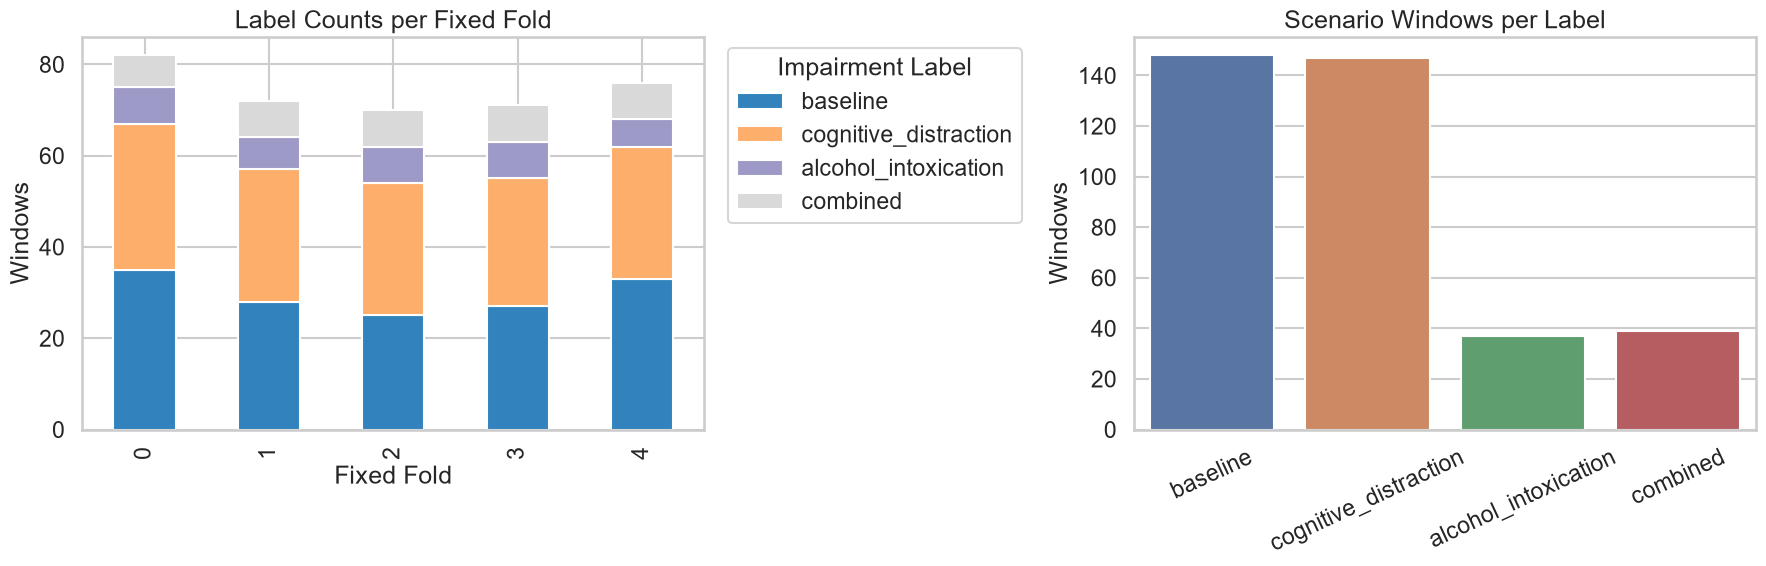

In [6]:
fold_label_counts = pd.crosstab(
    feature_table["fixed_fold"],
    feature_table["impairment_label"],
).reindex(columns=LABEL_ORDER, fill_value=0)

display(fold_label_counts)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

fold_label_counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20c")
axes[0].set_title("Label Counts per Fixed Fold")
axes[0].set_xlabel("Fixed Fold")
axes[0].set_ylabel("Windows")
axes[0].legend(title="Impairment Label", bbox_to_anchor=(1.02, 1), loc="upper left")

label_counts = feature_table["impairment_label"].value_counts().reindex(LABEL_ORDER, fill_value=0)
sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[1], palette="deep")
axes[1].set_title("Scenario Windows per Label")
axes[1].set_xlabel("")
axes[1].set_ylabel("Windows")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(artifact_dir / "label_balance.png", dpi=150, bbox_inches="tight")

## 3. Train and Compare the Handcrafted Baselines

In [7]:
logistic_regression = run_fixed_fold_logistic_baseline(
    feature_table,
    feature_columns=feature_columns,
    label_column="impairment_label",
    fold_column="fixed_fold",
    labels=LABEL_ORDER,
    c_value=1.0,
    class_weight="balanced",
    max_iter=2000,
)

linear_svm = run_fixed_fold_linear_svm_baseline(
    feature_table,
    feature_columns=feature_columns,
    label_column="impairment_label",
    fold_column="fixed_fold",
    labels=LABEL_ORDER,
    c_value=1.0,
    class_weight="balanced",
    max_iter=4000,
)

baselines = {
    "logistic_regression": logistic_regression,
    "linear_svm": linear_svm,
}

def save_baseline_outputs(model_name: str, result: dict) -> None:
    model_dir = artifact_dir / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    result["fold_metrics"].to_csv(model_dir / "fold_metrics.csv", index=False)
    result["predictions"].to_csv(model_dir / "predictions.csv", index=False)
    result["overall_confusion"].to_csv(model_dir / "overall_confusion.csv")
    result["per_class_report"].to_csv(model_dir / "per_class_report.csv")
    result["overall_metrics"].to_csv(model_dir / "overall_metrics.csv", header=["value"])

for model_name, result in baselines.items():
    save_baseline_outputs(model_name, result)

overall_comparison = pd.DataFrame(
    [result["overall_metrics"].to_dict() for result in baselines.values()]
).set_index("model_name")

fold_metrics = pd.concat([result["fold_metrics"] for result in baselines.values()], ignore_index=True)
per_class_report = pd.concat(
    [
        result["per_class_report"].reset_index().rename(columns={"index": "label"}).assign(model_name=model_name)
        for model_name, result in baselines.items()
    ],
    ignore_index=True,
)

overall_comparison.to_csv(artifact_dir / "model_comparison.csv")
per_class_report.to_csv(artifact_dir / "per_class_report_all_models.csv", index=False)

display(overall_comparison)
display(fold_metrics)
display(per_class_report)

,uar,precision_macro,recall_macro,f1_macro,accuracy,num_samples,num_features,num_folds
model_name,,,,,,,,
logistic_regression,0.439852,0.421643,0.439852,0.423321,0.498652,371,10,5
linear_svm,0.417289,0.413427,0.417289,0.412842,0.517520,371,10,5


,model_name,fixed_fold,num_train,num_test,uar,precision_macro,recall_macro,f1_macro,accuracy
0,logistic_regression,0,289,82,0.406920,0.407245,0.406920,0.400079,0.487805
1,logistic_regression,1,299,72,0.435345,0.382692,0.435345,0.381283,0.416667
2,logistic_regression,2,301,70,0.426466,0.403992,0.426466,0.372425,0.442857
3,logistic_regression,3,300,71,0.424934,0.420513,0.424934,0.421445,0.521127
4,logistic_regression,4,295,76,0.526580,0.507440,0.526580,0.510929,0.618421
5,linear_svm,0,289,82,0.421875,0.421271,0.421875,0.419600,0.512195
6,linear_svm,1,299,72,0.416256,0.396837,0.416256,0.400449,0.458333
7,linear_svm,2,301,70,0.382586,0.346181,0.382586,0.337091,0.442857
8,linear_svm,3,300,71,0.480489,0.641650,0.480489,0.500879,0.605634
9,linear_svm,4,295,76,0.402332,0.413614,0.402332,0.404832,0.565789


,label,precision,recall,f1,support,model_name
0,baseline,0.633803,0.608108,0.620690,148,logistic_regression
1,cognitive_distraction,0.594828,0.469388,0.524715,147,logistic_regression
2,alcohol_intoxication,0.203704,0.297297,0.241758,37,logistic_regression
3,combined,0.254237,0.384615,0.306122,39,logistic_regression
4,baseline,0.606061,0.675676,0.638978,148,linear_svm
5,cognitive_distraction,0.584000,0.496599,0.536765,147,linear_svm
6,alcohol_intoxication,0.218750,0.189189,0.202899,37,linear_svm
7,combined,0.244898,0.307692,0.272727,39,linear_svm


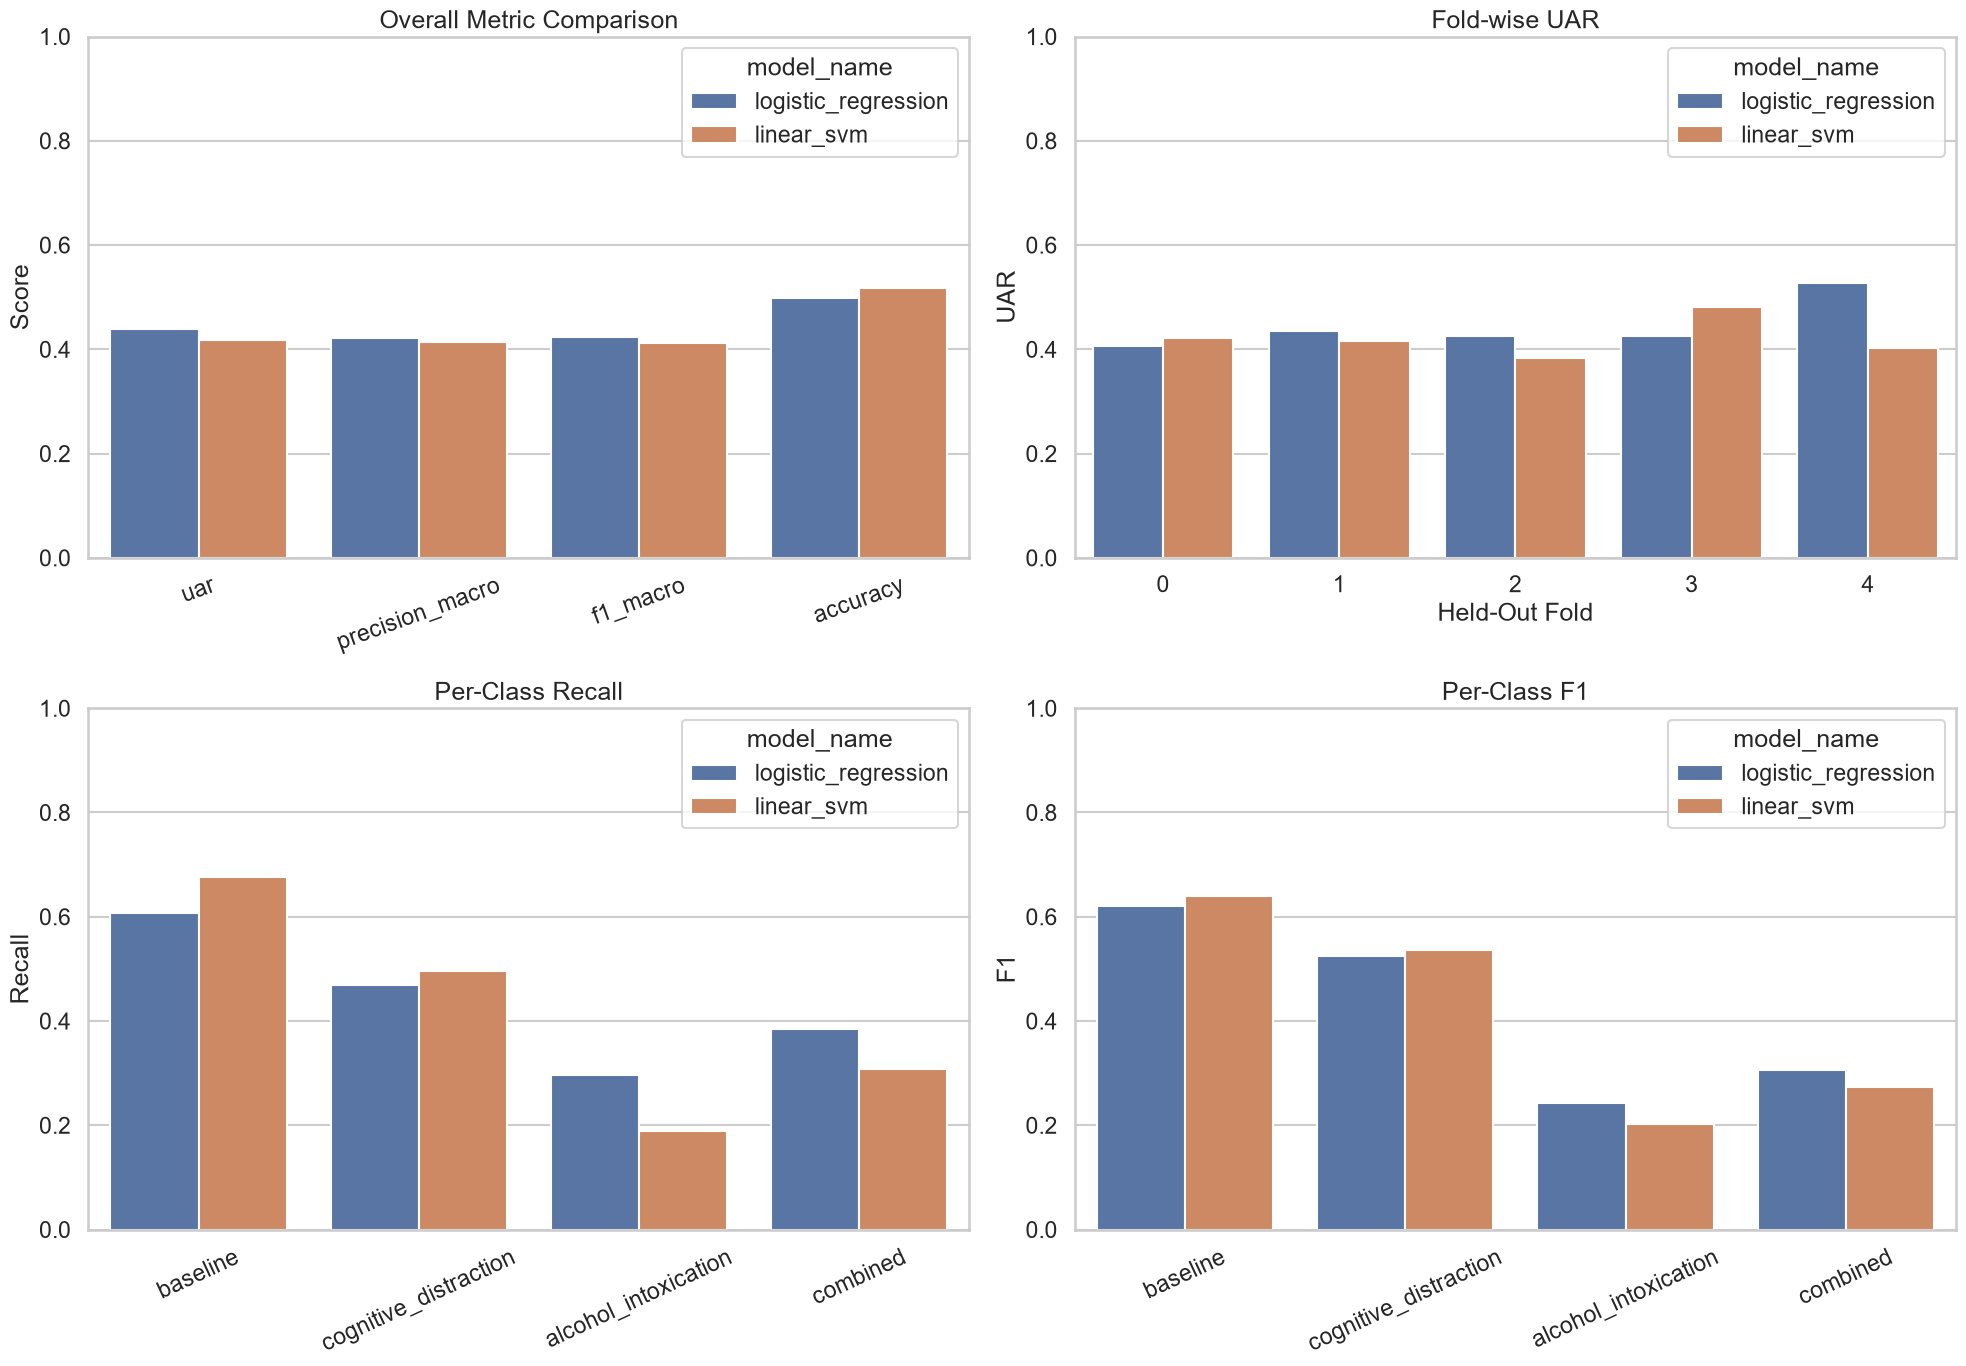

In [8]:
metric_plot = (
    overall_comparison[["uar", "precision_macro", "f1_macro", "accuracy"]]
    .reset_index()
    .melt(id_vars="model_name", var_name="metric", value_name="score")
)

fig, axes = plt.subplots(2, 2, figsize=(20, 14))

sns.barplot(data=metric_plot, x="metric", y="score", hue="model_name", ax=axes[0, 0])
axes[0, 0].set_title("Overall Metric Comparison")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Score")
axes[0, 0].set_ylim(0.0, 1.0)
axes[0, 0].tick_params(axis="x", rotation=20)

sns.barplot(data=fold_metrics, x="fixed_fold", y="uar", hue="model_name", ax=axes[0, 1])
axes[0, 1].set_title("Fold-wise UAR")
axes[0, 1].set_xlabel("Held-Out Fold")
axes[0, 1].set_ylabel("UAR")
axes[0, 1].set_ylim(0.0, 1.0)

sns.barplot(data=per_class_report, x="label", y="recall", hue="model_name", ax=axes[1, 0])
axes[1, 0].set_title("Per-Class Recall")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Recall")
axes[1, 0].set_ylim(0.0, 1.0)
axes[1, 0].tick_params(axis="x", rotation=25)

sns.barplot(data=per_class_report, x="label", y="f1", hue="model_name", ax=axes[1, 1])
axes[1, 1].set_title("Per-Class F1")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("F1")
axes[1, 1].set_ylim(0.0, 1.0)
axes[1, 1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(artifact_dir / "model_comparison_plots.png", dpi=150, bbox_inches="tight")

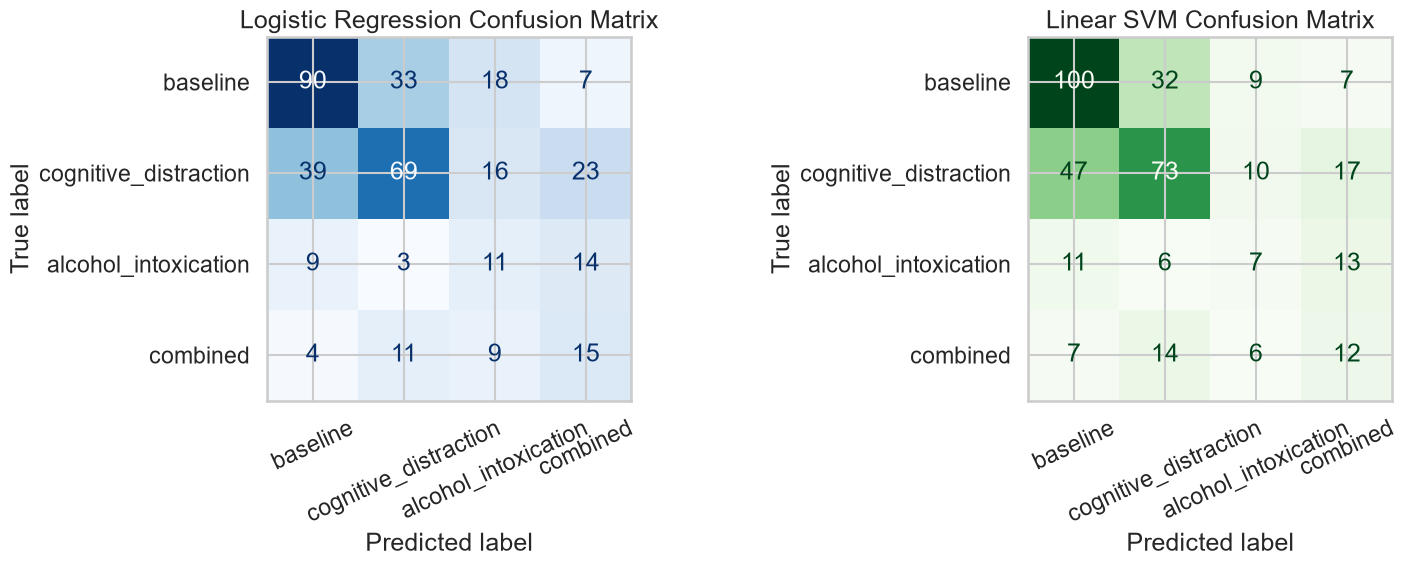

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

logistic_display = ConfusionMatrixDisplay(
    confusion_matrix=logistic_regression["overall_confusion"].to_numpy(),
    display_labels=logistic_regression["overall_confusion"].index.to_list(),
)
logistic_display.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].tick_params(axis="x", rotation=25)

svm_display = ConfusionMatrixDisplay(
    confusion_matrix=linear_svm["overall_confusion"].to_numpy(),
    display_labels=linear_svm["overall_confusion"].index.to_list(),
)
svm_display.plot(ax=axes[1], cmap="Greens", values_format="d", colorbar=False)
axes[1].set_title("Linear SVM Confusion Matrix")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(artifact_dir / "confusion_matrices.png", dpi=150, bbox_inches="tight")

## 4. Auxiliary Binary Task: Intoxicated vs Not Intoxicated

In [10]:
binary_feature_table = feature_table.copy()
binary_feature_table["intoxication_label"] = np.where(
    binary_feature_table["intoxicated"],
    "intoxicated",
    "not_intoxicated",
)
binary_labels = ["not_intoxicated", "intoxicated"]

binary_logistic_regression = run_fixed_fold_logistic_baseline(
    binary_feature_table,
    feature_columns=feature_columns,
    label_column="intoxication_label",
    fold_column="fixed_fold",
    labels=binary_labels,
    c_value=1.0,
    class_weight="balanced",
    max_iter=2000,
)

binary_dir = artifact_dir / "binary_intoxication_logreg"
binary_dir.mkdir(parents=True, exist_ok=True)

binary_logistic_regression["fold_metrics"].to_csv(binary_dir / "fold_metrics.csv", index=False)
binary_logistic_regression["predictions"].to_csv(binary_dir / "predictions.csv", index=False)
binary_logistic_regression["overall_confusion"].to_csv(binary_dir / "overall_confusion.csv")
binary_logistic_regression["per_class_report"].to_csv(binary_dir / "classification_report.csv")
binary_logistic_regression["overall_metrics"].to_csv(binary_dir / "overall_metrics.csv", header=["value"])

display(binary_logistic_regression["fold_metrics"])
display(binary_logistic_regression["overall_metrics"].to_frame("value"))
display(binary_logistic_regression["per_class_report"])

,model_name,fixed_fold,num_train,num_test,uar,precision_macro,recall_macro,f1_macro,accuracy
0,logistic_regression,0,289,82,0.665672,0.612121,0.665672,0.615925,0.707317
1,logistic_regression,1,299,72,0.750877,0.672013,0.750877,0.672727,0.722222
2,logistic_regression,2,301,70,0.726852,0.666667,0.726852,0.668561,0.714286
3,logistic_regression,3,300,71,0.677273,0.677273,0.677273,0.677273,0.774648
4,logistic_regression,4,295,76,0.693548,0.693548,0.693548,0.693548,0.815789


,value
model_name,logistic_regression
uar,0.703925
precision_macro,0.656052
recall_macro,0.703925
f1_macro,0.667487
accuracy,0.746631
num_samples,371
num_features,10
num_folds,5


,precision,recall,f1,support
not_intoxicated,0.891051,0.776271,0.829710,295
intoxicated,0.421053,0.631579,0.505263,76


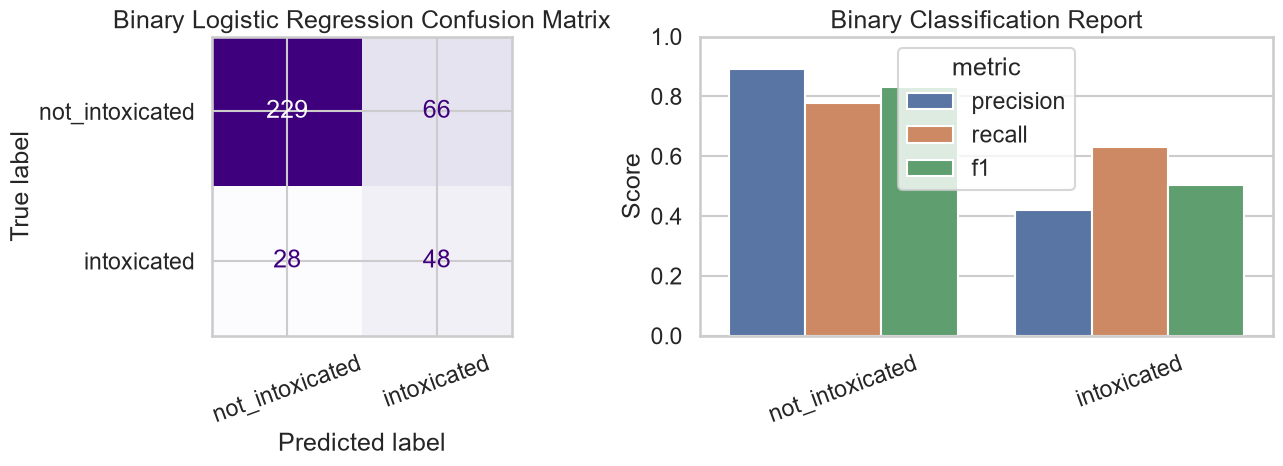

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

binary_display = ConfusionMatrixDisplay(
    confusion_matrix=binary_logistic_regression["overall_confusion"].to_numpy(),
    display_labels=binary_logistic_regression["overall_confusion"].index.to_list(),
)
binary_display.plot(ax=axes[0], cmap="Purples", values_format="d", colorbar=False)
axes[0].set_title("Binary Logistic Regression Confusion Matrix")
axes[0].tick_params(axis="x", rotation=20)

binary_report_plot = (
    binary_logistic_regression["per_class_report"]
    .reset_index()
    .rename(columns={"index": "label"})
    .melt(id_vars=["label", "support"], value_vars=["precision", "recall", "f1"], var_name="metric", value_name="score")
)
sns.barplot(data=binary_report_plot, x="label", y="score", hue="metric", ax=axes[1])
axes[1].set_title("Binary Classification Report")
axes[1].set_xlabel("")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.0, 1.0)
axes[1].tick_params(axis="x", rotation=20)

fig.tight_layout()
fig.savefig(binary_dir / "binary_results.png", dpi=150, bbox_inches="tight")